# N-CMAPSS Ortak Veri Hazırlama Doğrulaması

Bu notebook ortak preprocessing çıktılarının anlaşılır biçimde incelenmesini sağlar. Otomatik testlerin yerine geçmez; metadata, fold ve örnek sensör pencerelerini görselleştirir.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

current_dir = Path.cwd().resolve()
repo_root = next(
    path for path in (current_dir, *current_dir.parents)
    if (path / 'n_cmapss').is_dir()
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from n_cmapss.preprocessing.config import OUTPUT_DIR, WINDOW_SIZE, STRIDE
from n_cmapss.preprocessing.data_loader import (
    NCmapssDataLoader,
    load_feature_names,
    load_window_metadata,
    split_windows_by_fold,
)
from n_cmapss.preprocessing.validate_outputs import (
    validate_data_loader,
    validate_output_files,
    validate_split_folds,
    validate_window_metadata,
    validate_windows_against_hdf5,
)

plt.style.use('seaborn-v0_8-whitegrid')
print(f'Repo: {repo_root}')
print(f'Window size: {WINDOW_SIZE}, stride: {STRIDE}')

Repo: /Users/ilkinsoydas/Desktop/projeler/vscode/predictive-maintance
Window size: 256, stride: 1024


## 1. Otomatik bütünlük kontrolleri

Aşağıdaki kontroller çıktı dosyalarını, pencere sınırlarını, HDF5 uyumunu, motor fold'larını ve loader çıktısını doğrular.

In [2]:
validation_steps = [
    ('Çıktı dosyaları', validate_output_files),
    ('Pencere metadata', validate_window_metadata),
    ('HDF5 pencere uyumu', validate_windows_against_hdf5),
    ('Motor fold ayrımı', validate_split_folds),
    ('Ortak data loader', validate_data_loader),
]

validation_results = []
for check_name, check_function in validation_steps:
    try:
        check_function()
        validation_results.append({'Kontrol': check_name, 'Sonuç': 'BAŞARILI'})
    except Exception as error:
        validation_results.append({'Kontrol': check_name, 'Sonuç': f'HATA: {error}'})

pd.DataFrame(validation_results)

Valid output file: window_metadata.csv
Valid output file: split_folds.json

Window metadata validation passed.
Windows checked: 5,270

HDF5 window validation passed.
Windows compared with HDF5: 5,270

Split fold validation passed.
Folds checked: 6
Development units: [2, 5, 10, 16, 18, 20]
Official test units: [11, 14, 15]

Data loader validation passed.
Windows loaded: 5,270


,Kontrol,Sonuç
0,Çıktı dosyaları,BAŞARILI
1,Pencere metadata,BAŞARILI
2,HDF5 pencere uyumu,BAŞARILI
3,Motor fold ayrımı,BAŞARILI
4,Ortak data loader,BAŞARILI


## 2. Ortak veri özeti

In [3]:
metadata = pd.read_csv(OUTPUT_DIR / 'window_metadata.csv')
feature_names = load_feature_names()

summary = pd.DataFrame({
    'Metrik': [
        'Pencere sayısı',
        'Seçilen ham satır',
        'Motor sayısı',
        'Uçuş sayısı',
        'Özellik sayısı',
        'Pencere uzunluğu',
        'Stride',
    ],
    'Değer': [
        len(metadata),
        len(metadata) * WINDOW_SIZE,
        metadata['unit'].nunique(),
        metadata[['unit', 'cycle']].drop_duplicates().shape[0],
        len(feature_names),
        WINDOW_SIZE,
        STRIDE,
    ],
})
summary

,Metrik,Değer
0,Pencere sayısı,5270
1,Seçilen ham satır,1349120
2,Motor sayısı,6
3,Uçuş sayısı,446
4,Özellik sayısı,18
5,Pencere uzunluğu,256
6,Stride,1024


In [4]:
pd.DataFrame({
    'Sıra': range(len(feature_names)),
    'Özellik': feature_names,
    'Grup': ['Çalışma koşulu'] * 4 + ['Fiziksel sensör'] * 14,
})

,Sıra,Özellik,Grup
0,0,alt,Çalışma koşulu
1,1,Mach,Çalışma koşulu
2,2,TRA,Çalışma koşulu
3,3,T2,Çalışma koşulu
4,4,T24,Fiziksel sensör
5,5,T30,Fiziksel sensör
6,6,T48,Fiziksel sensör
7,7,T50,Fiziksel sensör
8,8,P15,Fiziksel sensör
9,9,P2,Fiziksel sensör


## 3. Motor ve RUL dağılımları

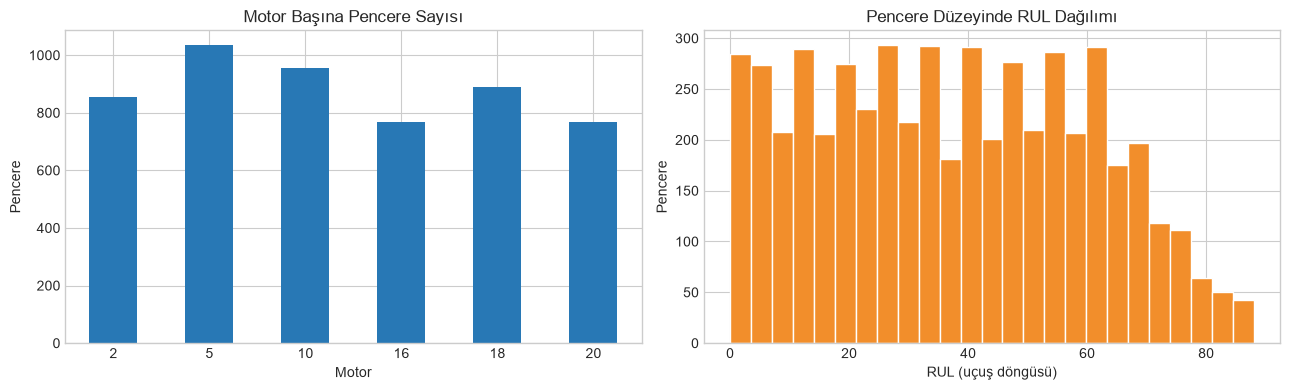

In [5]:
window_counts = metadata.groupby('unit').size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
window_counts.plot(kind='bar', ax=axes[0], color='#2878B5')
axes[0].set_title('Motor Başına Pencere Sayısı')
axes[0].set_xlabel('Motor')
axes[0].set_ylabel('Pencere')
axes[0].tick_params(axis='x', rotation=0)

axes[1].hist(metadata['rul'], bins=25, color='#F28E2B', edgecolor='white')
axes[1].set_title('Pencere Düzeyinde RUL Dağılımı')
axes[1].set_xlabel('RUL (uçuş döngüsü)')
axes[1].set_ylabel('Pencere')
plt.tight_layout()
plt.show()

## 4. Leave-One-Engine-Out fold özeti

In [6]:
with (OUTPUT_DIR / 'split_folds.json').open(encoding='utf-8') as split_file:
    split_config = json.load(split_file)

fold_rows = []
for fold in split_config['folds']:
    train_windows, validation_windows = split_windows_by_fold(
        load_window_metadata(),
        fold['fold'],
    )
    fold_rows.append({
        'Fold': fold['fold'],
        'Train motorları': ', '.join(map(str, fold['train_units'])),
        'Validation motoru': fold['validation_units'][0],
        'Train penceresi': len(train_windows),
        'Validation penceresi': len(validation_windows),
    })

pd.DataFrame(fold_rows)

,Fold,Train motorları,Validation motoru,Train penceresi,Validation penceresi
0,1,"5, 10, 16, 18, 20",2,4416,854
1,2,"2, 10, 16, 18, 20",5,4236,1034
2,3,"2, 5, 16, 18, 20",10,4315,955
3,4,"2, 5, 10, 18, 20",16,4502,768
4,5,"2, 5, 10, 16, 20",18,4380,890
5,6,"2, 5, 10, 16, 18",20,4501,769


## 5. Örnek ham pencere

İlk pencerenin 18 ortak girdisi aşağıda gösterilir. Bunlar henüz normalize edilmemiş ham değerlerdir.

window_id=0, unit=2, cycle=1, RUL=74.0, shape=(256, 18)


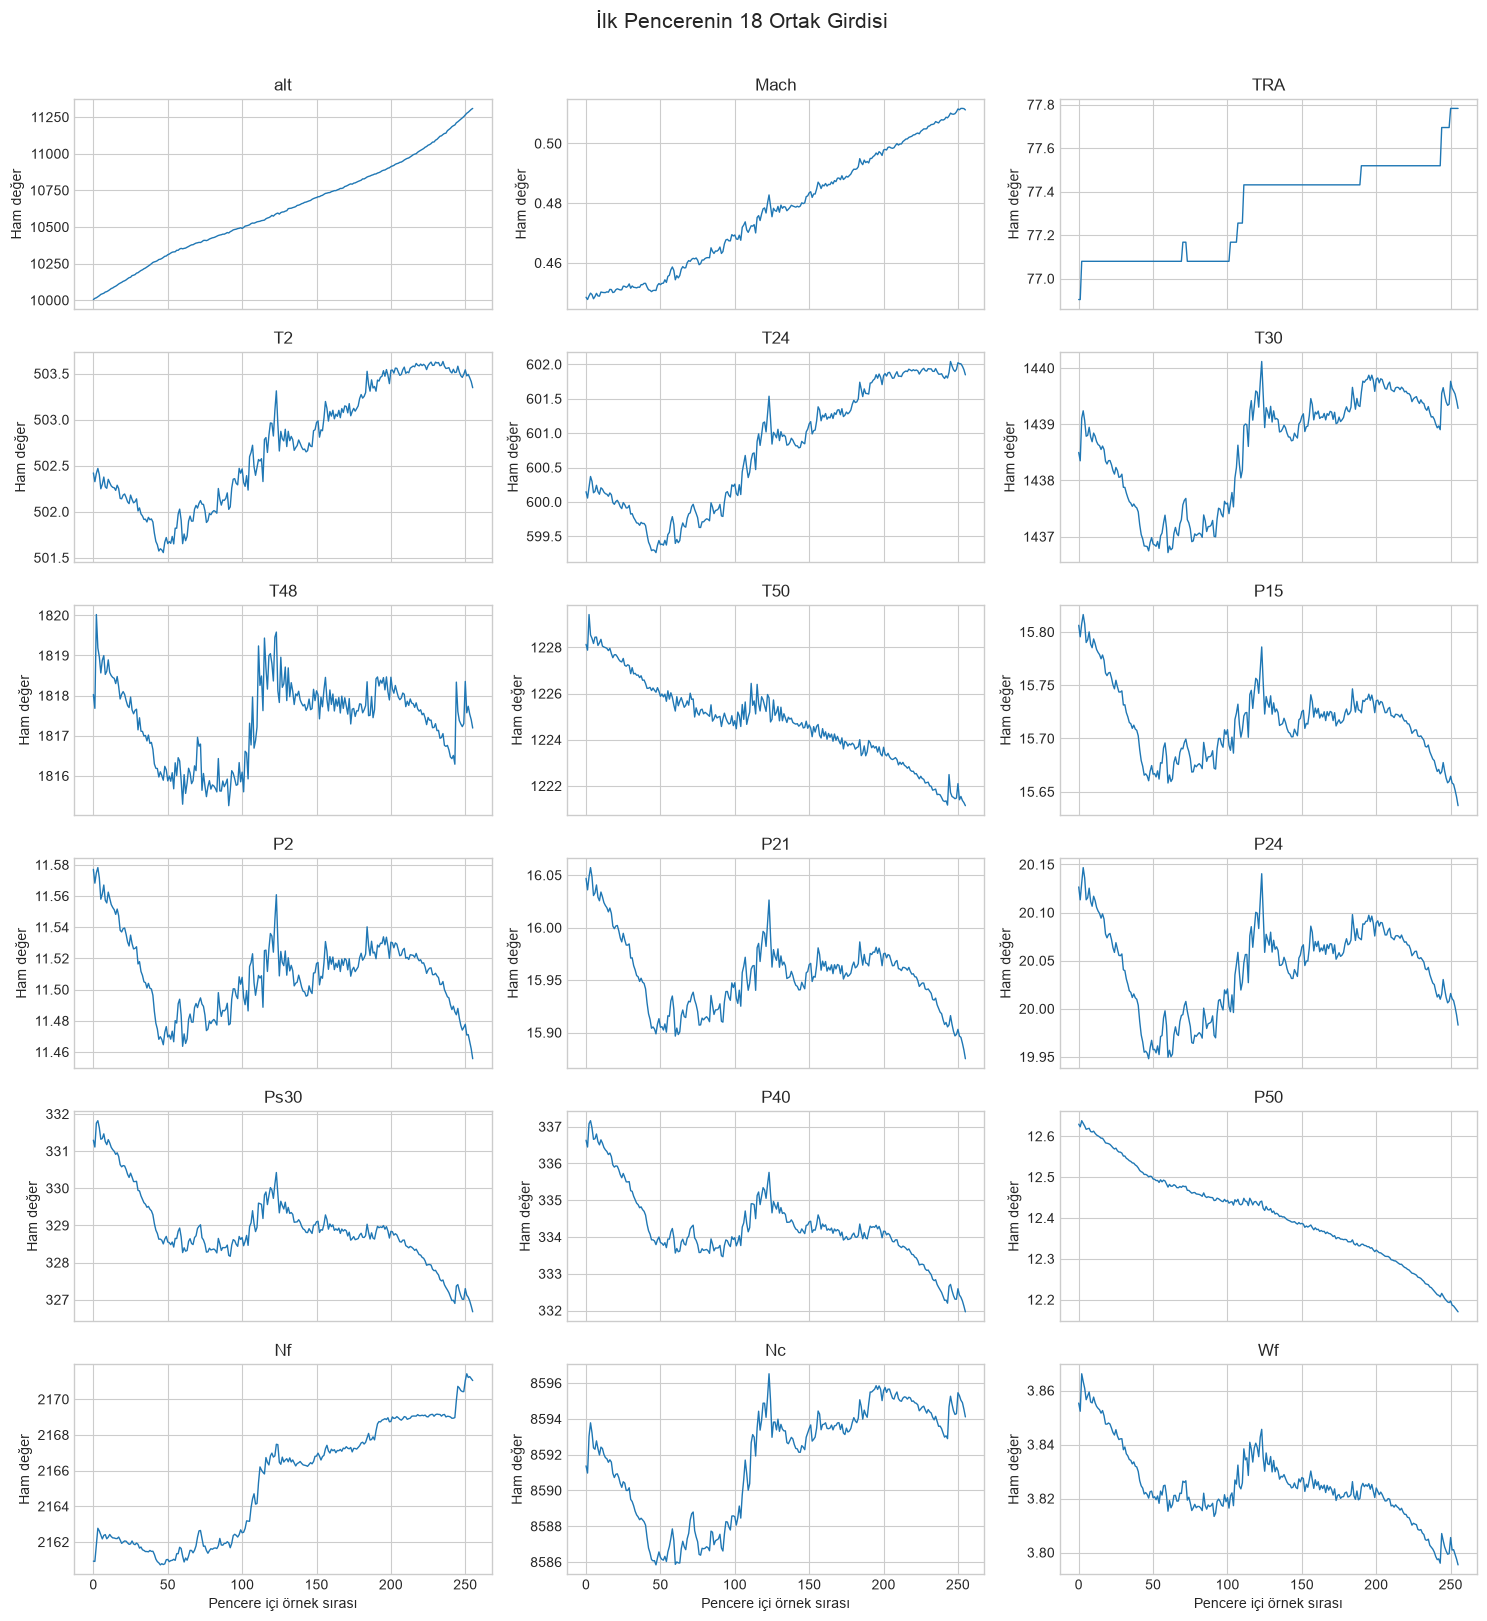

In [7]:
windows = load_window_metadata()
sample_record = windows[0]

with NCmapssDataLoader() as loader:
    sample_features, sample_target = loader.load_window(sample_record)

print(
    f'window_id={sample_record.window_id}, unit={sample_record.unit}, '
    f'cycle={sample_record.cycle}, RUL={sample_target}, shape={sample_features.shape}'
)

fig, axes = plt.subplots(6, 3, figsize=(15, 16), sharex=True)
for feature_index, (axis, feature_name) in enumerate(zip(axes.flat, feature_names)):
    axis.plot(sample_features[:, feature_index], linewidth=1)
    axis.set_title(feature_name)
    axis.set_ylabel('Ham değer')
for axis in axes[-1]:
    axis.set_xlabel('Pencere içi örnek sırası')
fig.suptitle('İlk Pencerenin 18 Ortak Girdisi', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

## Sonuç

- Ortak model girdisi sırası: 4 çalışma koşulu + 14 fiziksel sensör.
- Her pencere 256 ardışık satır içerir; stride 1024'tür.
- Train/validation ayrımı satır bazlı değil motor bazlıdır.
- Resmî test motorları 11, 14 ve 15 bu geliştirme verisine dahil değildir.
- Model ekipleri aynı metadata, fold tanımı ve data loader'ı kullanmalıdır.